In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,confusion_matrix)
from xgboost import XGBClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (LSTM,Dense,Dropout,Input)
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
df = pd.read_csv("air_compressor_metro.csv")

In [3]:
df = df.drop(columns = 'Unnamed: 0')

In [4]:
df = df.sort_values("timestamp").reset_index(drop = True)


In [5]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [6]:
df = df.set_index("timestamp")

In [7]:
failure_events = [
    {
        "failure_id": 1,
        "start": pd.Timestamp("2020-04-18 00:00:00"),
        "end": pd.Timestamp("2020-04-18 23:59:00")
    },
    {
        "failure_id": 2,
        "start": pd.Timestamp("2020-05-29 23:30:00"),
        "end": pd.Timestamp("2020-05-30 06:00:00")
    },
    {
        "failure_id": 3,
        "start": pd.Timestamp("2020-06-05 10:00:00"),
        "end": pd.Timestamp("2020-06-07 14:30:00")
    },
    {
        "failure_id": 4,
        "start": pd.Timestamp("2020-07-15 14:30:00"),
        "end": pd.Timestamp("2020-07-15 19:00:00")
    }
]

In [8]:
df["failure"] = 0
for event in failure_events:
    start_event = event["start"]
    end_event = event["end"]
    mask = ((df.index >= start_event) & (df.index <= end_event))
    df.loc[mask, "failure"] = 1


In [9]:
df.value_counts("failure")

failure
0    1486994
1      29954
Name: count, dtype: int64

In [10]:
df_10min =  df.resample("10min").agg({    
    "TP2": ["mean", "std", "min", "max"],
    "TP3": ["mean", "std", "min", "max"],
    "H1": ["mean", "std", "min", "max"],
    "DV_pressure": ["mean", "std", "min", "max"],
    "Reservoirs": ["mean", "std", "min", "max"],
    "Oil_temperature": ["mean", "std", "min", "max"],
    "Motor_current": ["mean", "std", "min", "max"],
    "COMP": ["mean", "std"],
    "DV_eletric": ["mean", "std"],
    "Towers": ["mean", "std"],
    "failure": "max"})

In [11]:
df_10min.columns = ["_".join(col).strip("_") for col in df_10min.columns]

In [12]:
df_10min.value_counts("failure_max")

failure_max
0.0    25022
1.0      499
Name: count, dtype: int64

In [13]:
sensor_cols = ["TP2_mean","TP3_mean","H1_mean","DV_pressure_mean","Reservoirs_mean","Oil_temperature_mean","Motor_current_mean"]

In [14]:
for col in sensor_cols:
    df_10min[f"{col}_1h_mean"] = df_10min[col].rolling(6).mean()
    df_10min[f"{col}_1h_std"] = df_10min[col].rolling(6).std()

In [15]:
df_10min.isna().sum().sum()

np.int64(266535)

In [16]:
df_10min = df_10min.copy()

In [17]:
df_10min = df_10min.dropna()

In [18]:
df_10min.isna().sum().sum()

np.int64(0)

In [19]:
df_10min.shape

(24596, 49)

In [20]:
df_10min.value_counts("failure_max")

failure_max
0.0    24107
1.0      489
Name: count, dtype: int64

In [21]:
df_10min = df_10min.copy()

In [23]:
X = df_10min.drop(columns=["failure_max"])
y = df_10min["failure_max"]

In [24]:
failure_events

[{'failure_id': 1,
  'start': Timestamp('2020-04-18 00:00:00'),
  'end': Timestamp('2020-04-18 23:59:00')},
 {'failure_id': 2,
  'start': Timestamp('2020-05-29 23:30:00'),
  'end': Timestamp('2020-05-30 06:00:00')},
 {'failure_id': 3,
  'start': Timestamp('2020-06-05 10:00:00'),
  'end': Timestamp('2020-06-07 14:30:00')},
 {'failure_id': 4,
  'start': Timestamp('2020-07-15 14:30:00'),
  'end': Timestamp('2020-07-15 19:00:00')}]

In [41]:
folds = []
TEST_BEFORE = pd.Timedelta(days=3, hours=12)
TEST_AFTER = pd.Timedelta(days=3, hours=12)
for event in failure_events[1:]:
    start_event = event["start"] - TEST_BEFORE
    end_event = event["end"] + TEST_AFTER
    X_train_mask = X.index <= start_event 
    y_train_mask = y.index <= end_event
    X_test_mask =  (X.index >= start_event) & (X.index <= end_event) 
    y_test_mask =  (y.index >= start_event) & (y.index <= end_event)
    folds.append({"failure_id": event["failure_id"], "X_train_mask": X_train_mask, "y_train_mask": y_train_mask, "X_test_mask": X_test_mask, "y_test_mask": y_test_mask})
    print((y[y_train_mask] == 0).sum(), (y[y_test_mask]==0).sum(), (y[y_train_mask] == 1).sum(), (y[y_test_mask] == 1).sum())
   

13892 896 183 39
14558 738 461 278
19034 823 489 28


In [ ]:
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
SEQ_LEN = 12
THRESHOLD = 0.5
X = X.sort_index()
y = y.loc[X.index]
lstm_results = []
lstm_models = {}
lstm_predictions = {}

for fold in folds:

    failure_id = fold["failure_id"]

    print("\n" + "=" * 65)
    print(f"LSTM - Failure {failure_id}")
    print("=" * 65)

    train_mask = fold["X_train_mask"]
    test_mask = fold["X_test_mask"]

    X_train = X.loc[train_mask]
    y_train = y.loc[train_mask]

    X_test = X.loc[test_mask]
    y_test = y.loc[test_mask]
    #print(X_train)
    print("X_train:", X_train.shape)
    print("X_test:", X_test.shape)
    
    scaler = StandardScaler()
    scaler.fit(X_train)
    X_scaled = scaler.transform(X).astype(np.float32)

    X_seq = []
    for i in range(SEQ_LEN - 1, len(X_scaled)):
        sequence = X_scaled[i - SEQ_LEN + 1 : i + 1]
        X_seq.append(sequence)
    X_seq = np.array(X_seq, dtype=np.float32)
    y_seq = y.iloc[SEQ_LEN - 1:].to_numpy(dtype=np.int32)
    sequence_times = X.index[SEQ_LEN - 1:]

    train_seq_mask = sequence_times.isin(X_train.index)
    test_seq_mask = sequence_times.isin(X_test.index)
            
    X_train_seq = X_seq[train_seq_mask]
    y_train_seq = y_seq[train_seq_mask]
            
    X_test_seq = X_seq[test_seq_mask]
    y_test_seq = y_seq[test_seq_mask]
    test_times = sequence_times[test_seq_mask]

    print("X_seq.shape:", X_seq.shape)

    print("y_seq:", y_seq.shape)

    print("sequence_times:", sequence_times.shape)

    print("Training sequences:", X_train_seq.shape)
            
    print("Test sequences:", X_test_seq.shape)
            
    print("Training class counts:",pd.Series(y_train_seq).value_counts().to_dict())
            
    print("Test class counts:",pd.Series(y_test_seq).value_counts().to_dict())
            
        
    n_negative = int((y_train_seq == 0).sum())
    n_positive = int((y_train_seq == 1).sum())
    
    if n_positive == 0 or n_negative == 0:
        raise ValueError(f"Training fold {failure_id} does not contain both classes.")
    
    class_weight = {0: 1.0,1: n_negative / n_positive}
    
    print("Class weights:", class_weight)


    model = Sequential([
            Input(shape=(SEQ_LEN, X.shape[1])),
            LSTM(32),
            Dropout(0.2),
            Dense(16, activation="relu"),
            Dropout(0.2),
            Dense(1, activation="sigmoid")])
    
    model.compile(optimizer="adam",loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.Precision(name="precision"),tf.keras.metrics.Recall(name="recall")])


    early_stopping = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)
    
    
    history = model.fit(X_train_seq,y_train_seq,validation_split=0.15,epochs=20,batch_size=64,class_weight=class_weight,
                        callbacks=[early_stopping],shuffle=False,verbose=1)

    y_prob = model.predict(X_test_seq,verbose=0).ravel()

    y_pred = (y_prob >= THRESHOLD).astype(int)


    precision = precision_score(y_test_seq, y_pred, zero_division=0)
    
    recall = recall_score(y_test_seq, y_pred, zero_division=0)
    
    f1 = f1_score(y_test_seq, y_pred, zero_division=0)
    
    roc_auc = roc_auc_score(y_test_seq, y_prob)
    
    pr_auc = average_precision_score(y_test_seq, y_prob)
    
    cm = confusion_matrix(y_test_seq, y_pred, labels=[0, 1])
    
    tn, fp, fn, tp = cm.ravel()
    
    print("\nClassification Report:")
    print(classification_report(y_test_seq,y_pred,labels=[0, 1],target_names=["Healthy", "Failure"],zero_division=0,digits=4) )
    
    print("Confusion Matrix:")
    print(cm)
    
    print(f"Threshold: {THRESHOLD}")
    print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print(f"PR-AUC:    {pr_auc:.4f}")



LSTM - Failure 2
X_train: (13141, 48)
X_test: (935, 48)
X_seq.shape: (24585, 12, 48)
y_seq: (24585,)
sequence_times: (24585,)
Training sequences: (13130, 12, 48)
Test sequences: (935, 12, 48)
Training class counts: {0: 12986, 1: 144}
Test class counts: {0: 896, 1: 39}
Class weights: {0: 1.0, 1: 90.18055555555556}
Epoch 1/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 1.3917 - precision: 0.0082 - recall: 0.0347 - val_loss: 0.1068 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.7725 - precision: 0.3788 - recall: 0.7708 - val_loss: 0.2347 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3338 - precision: 0.3011 - recall: 0.9931 - val_loss: 0.4145 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1694 - precision: 0.2775 - recall: 1.0000 - val_loss: 0.4418 - val_precision: 0.0000e+00 - val

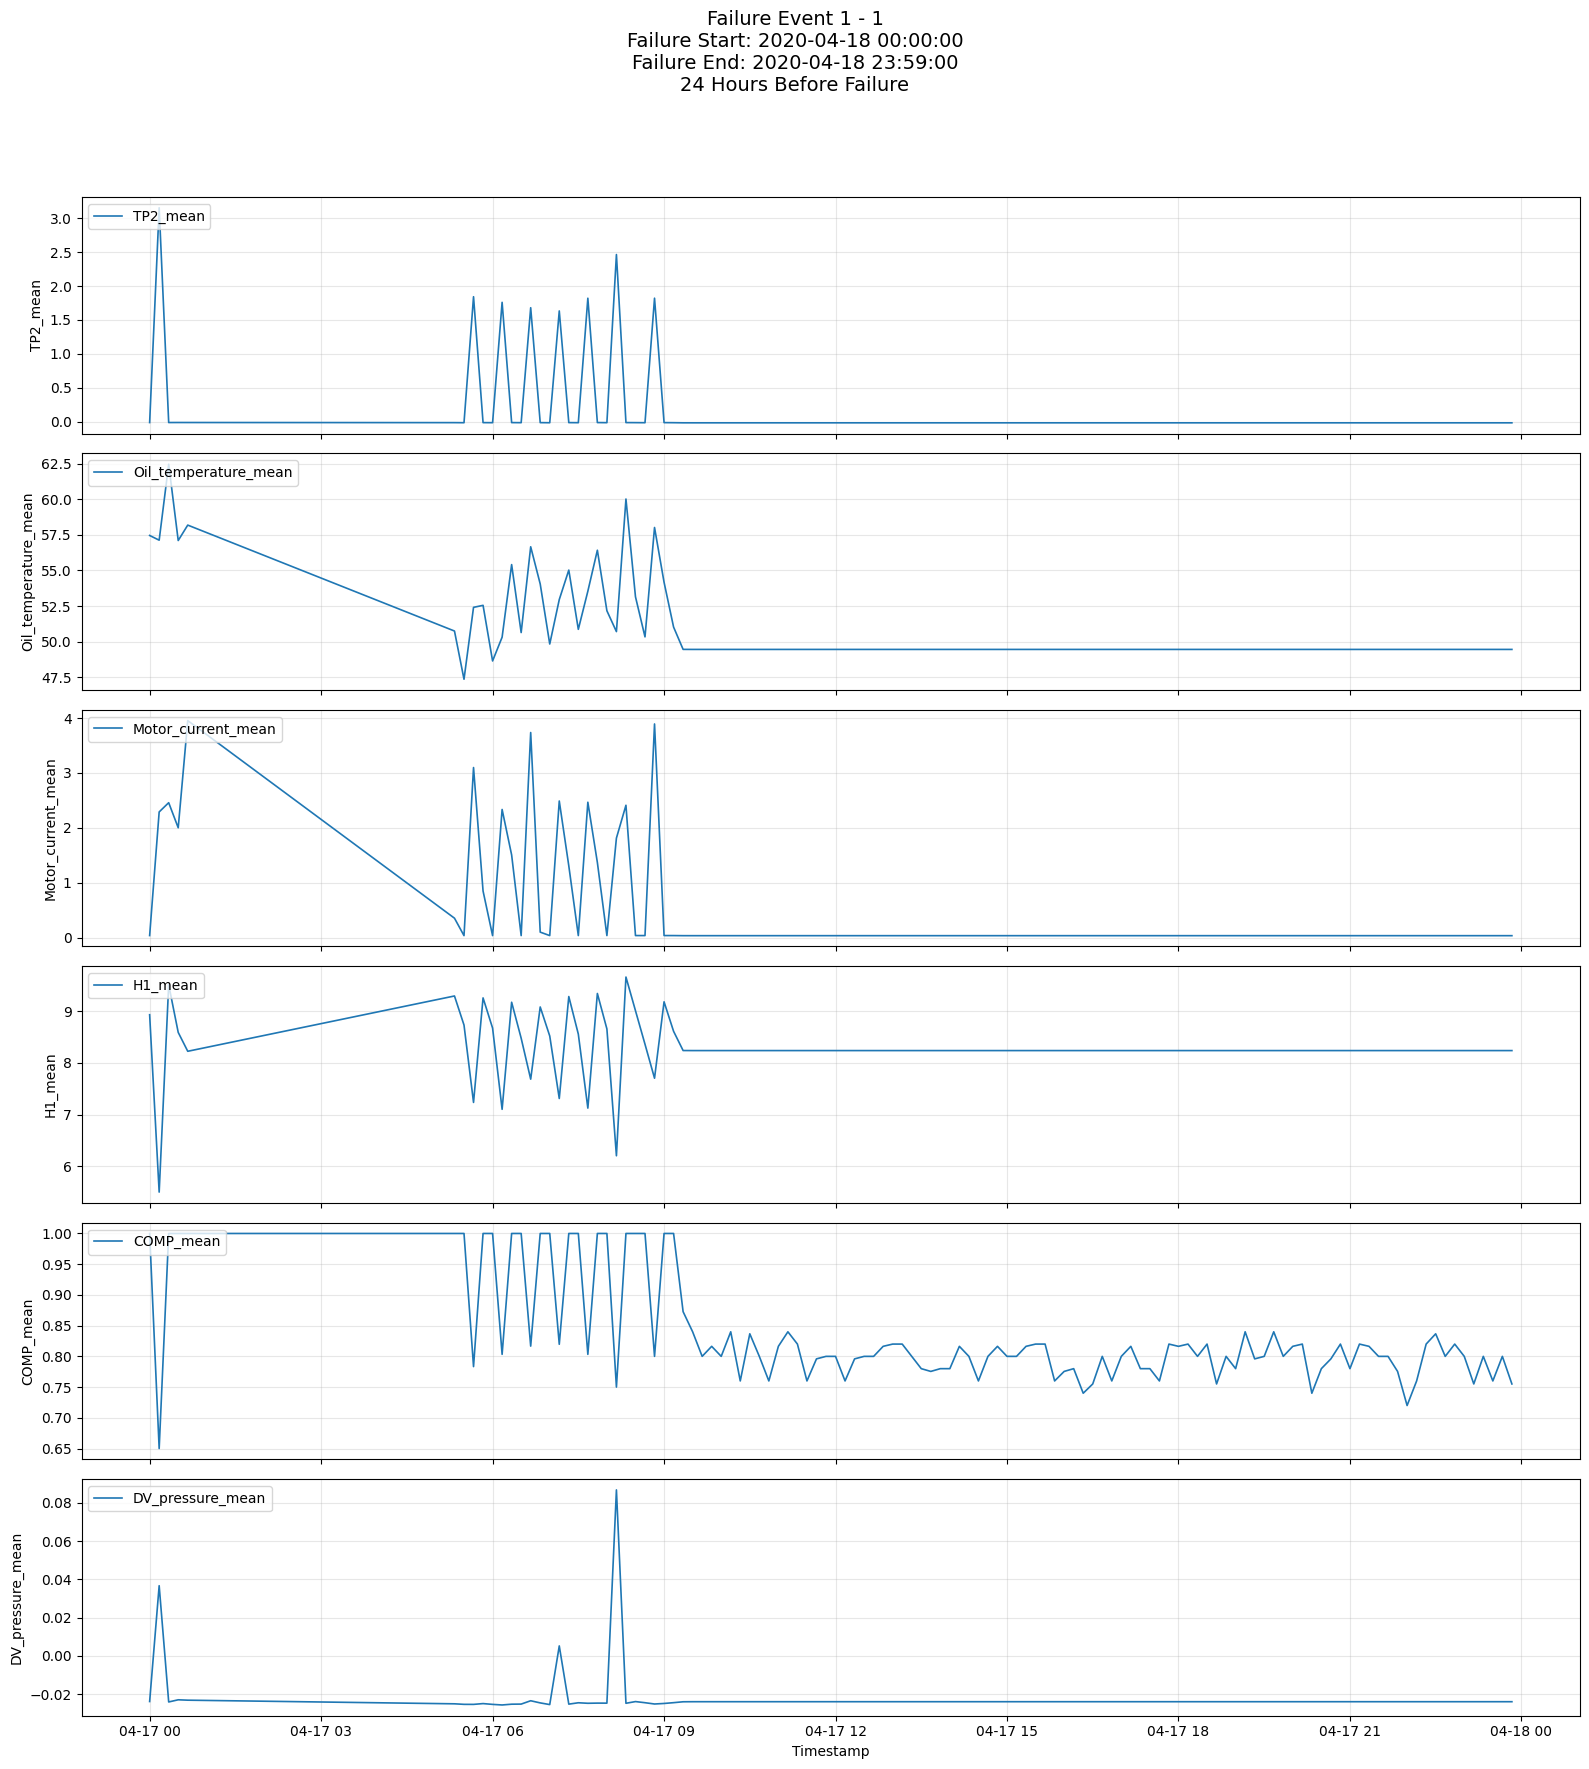

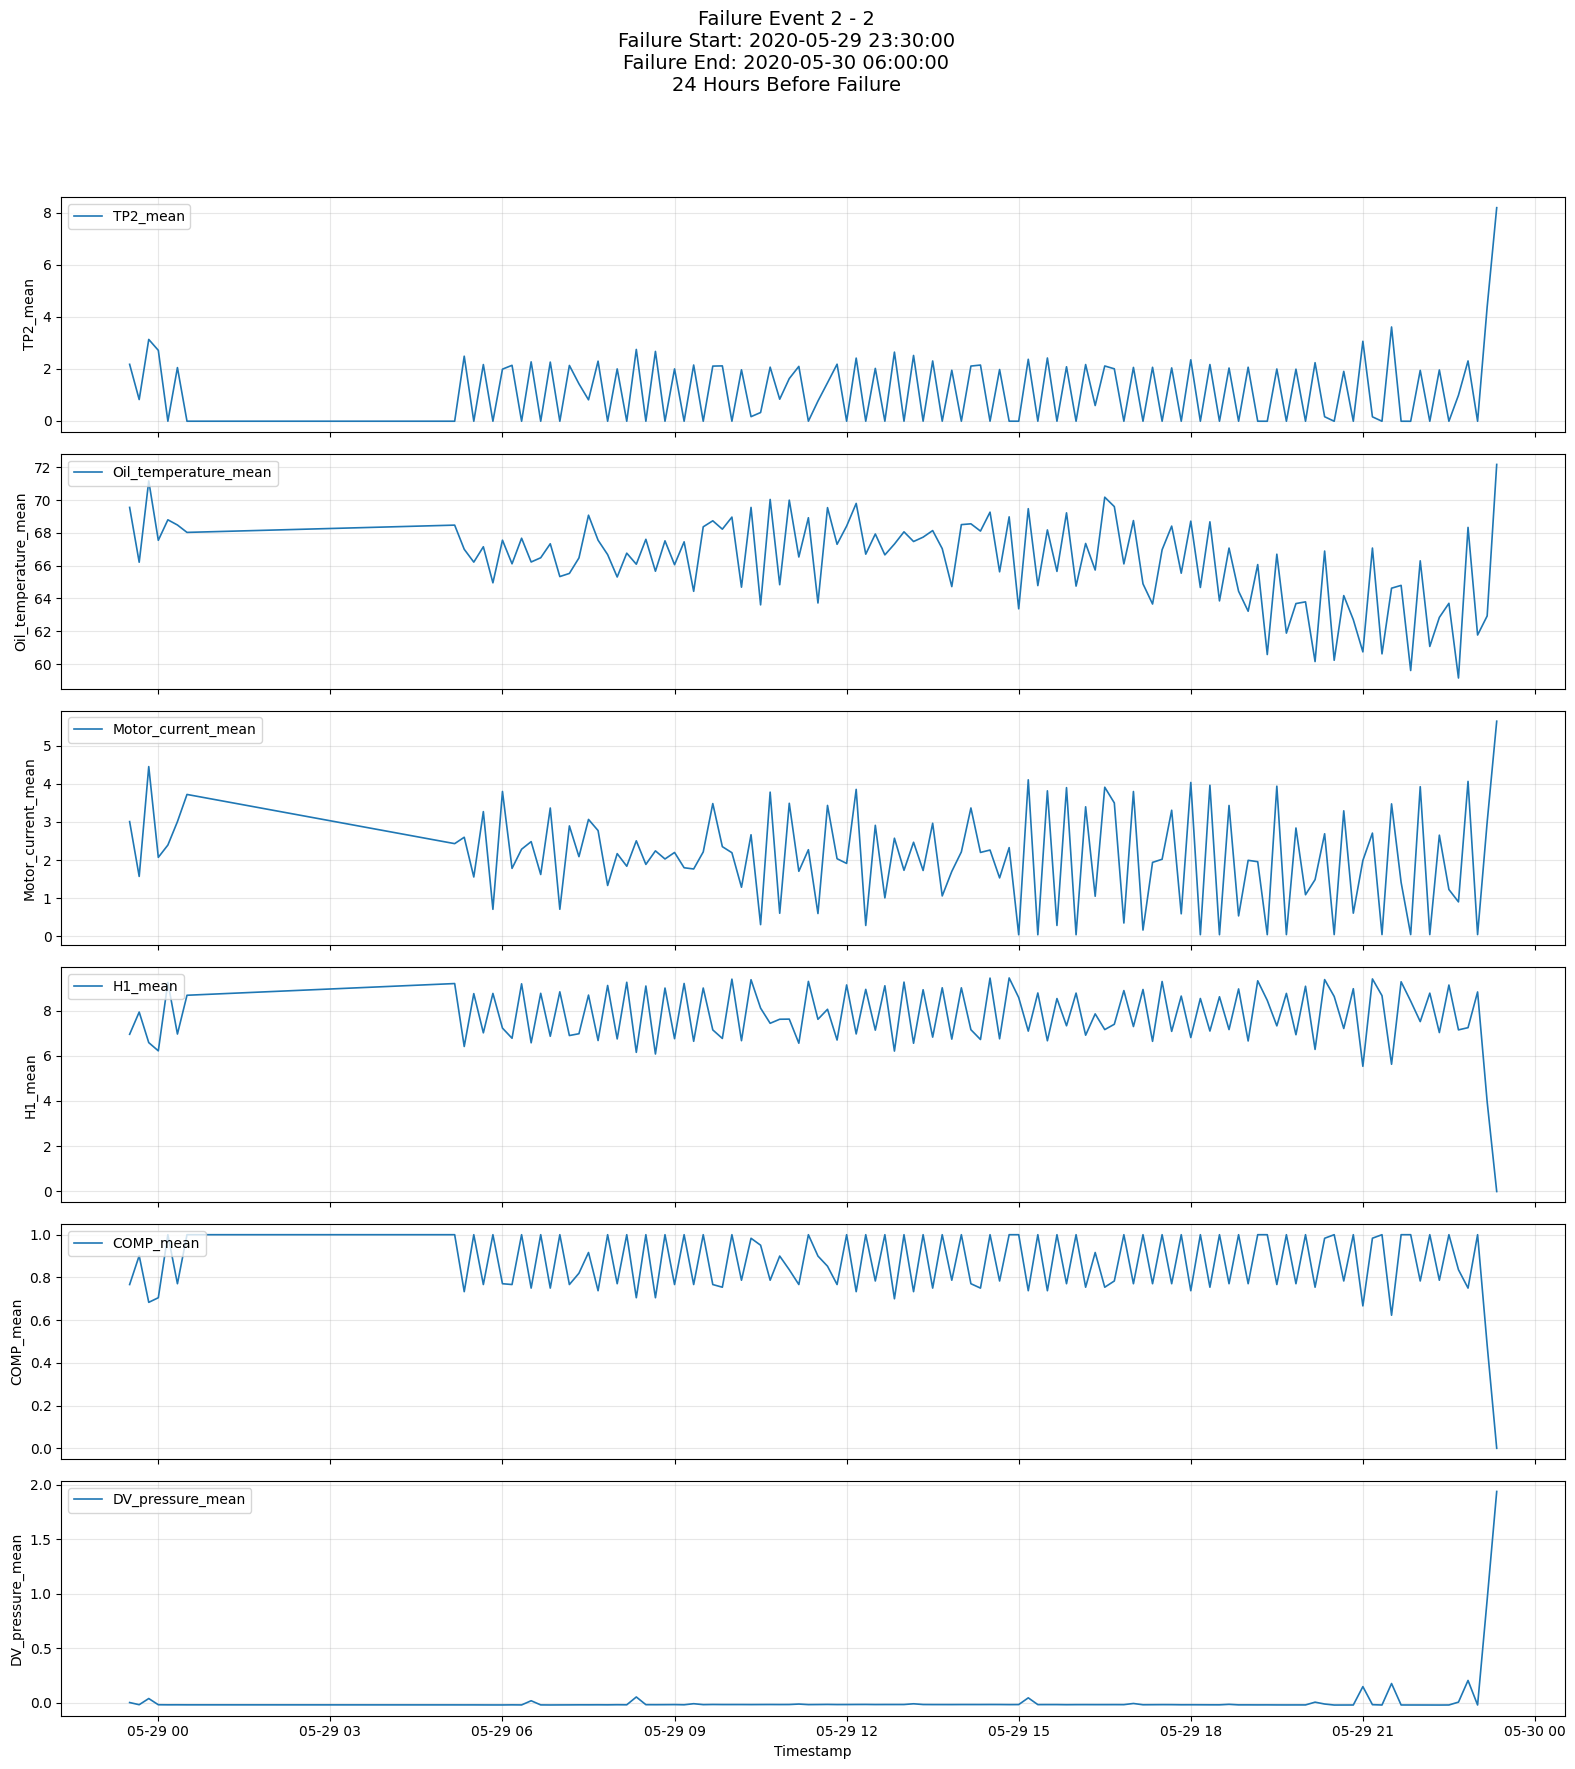

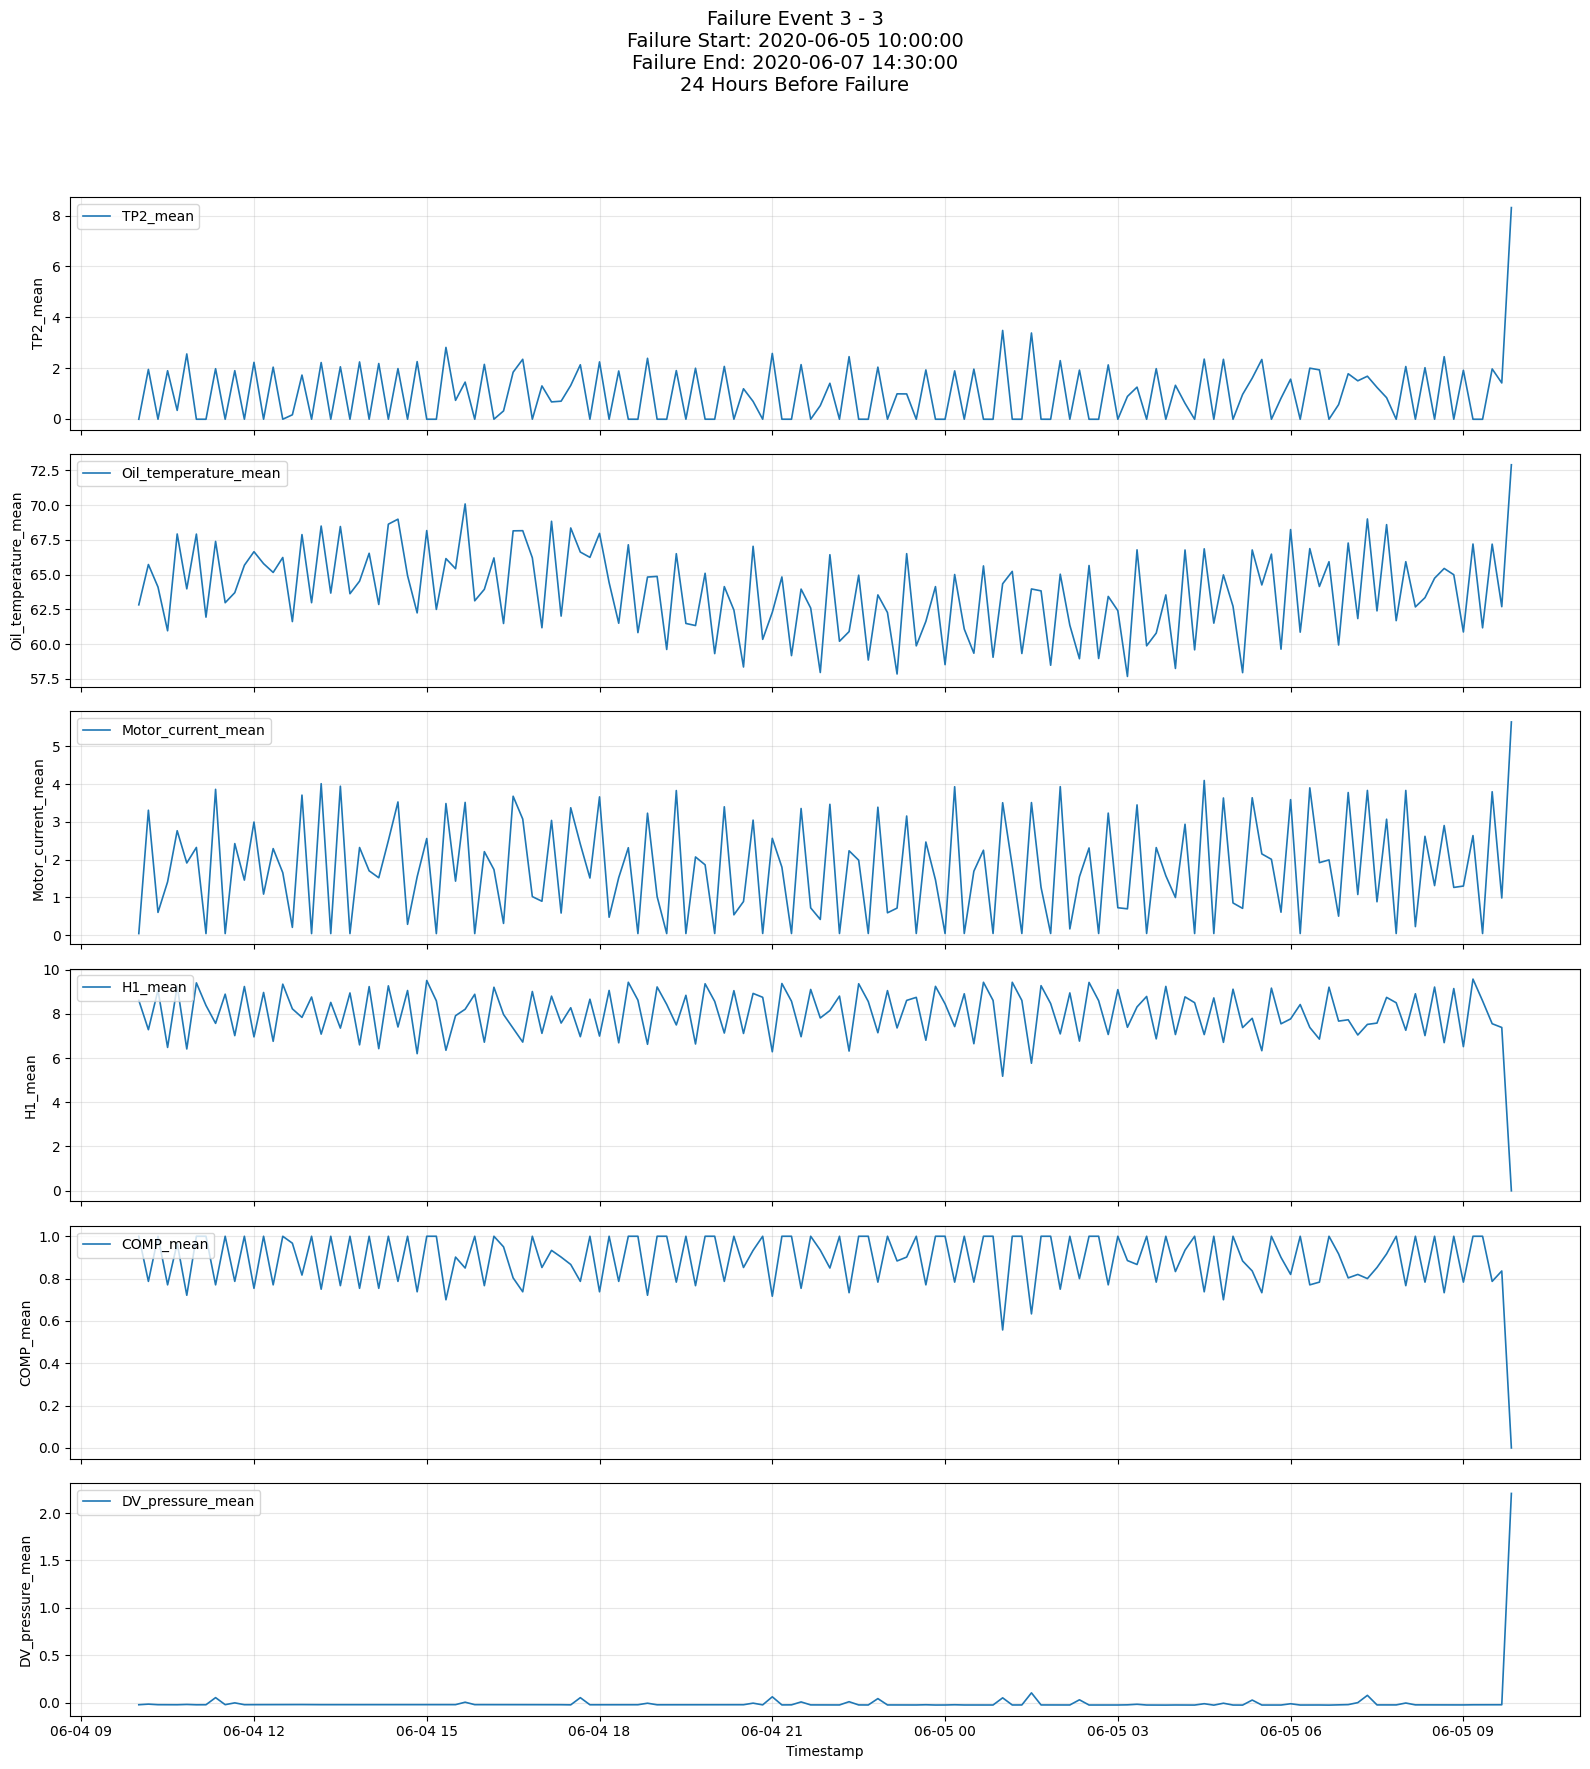

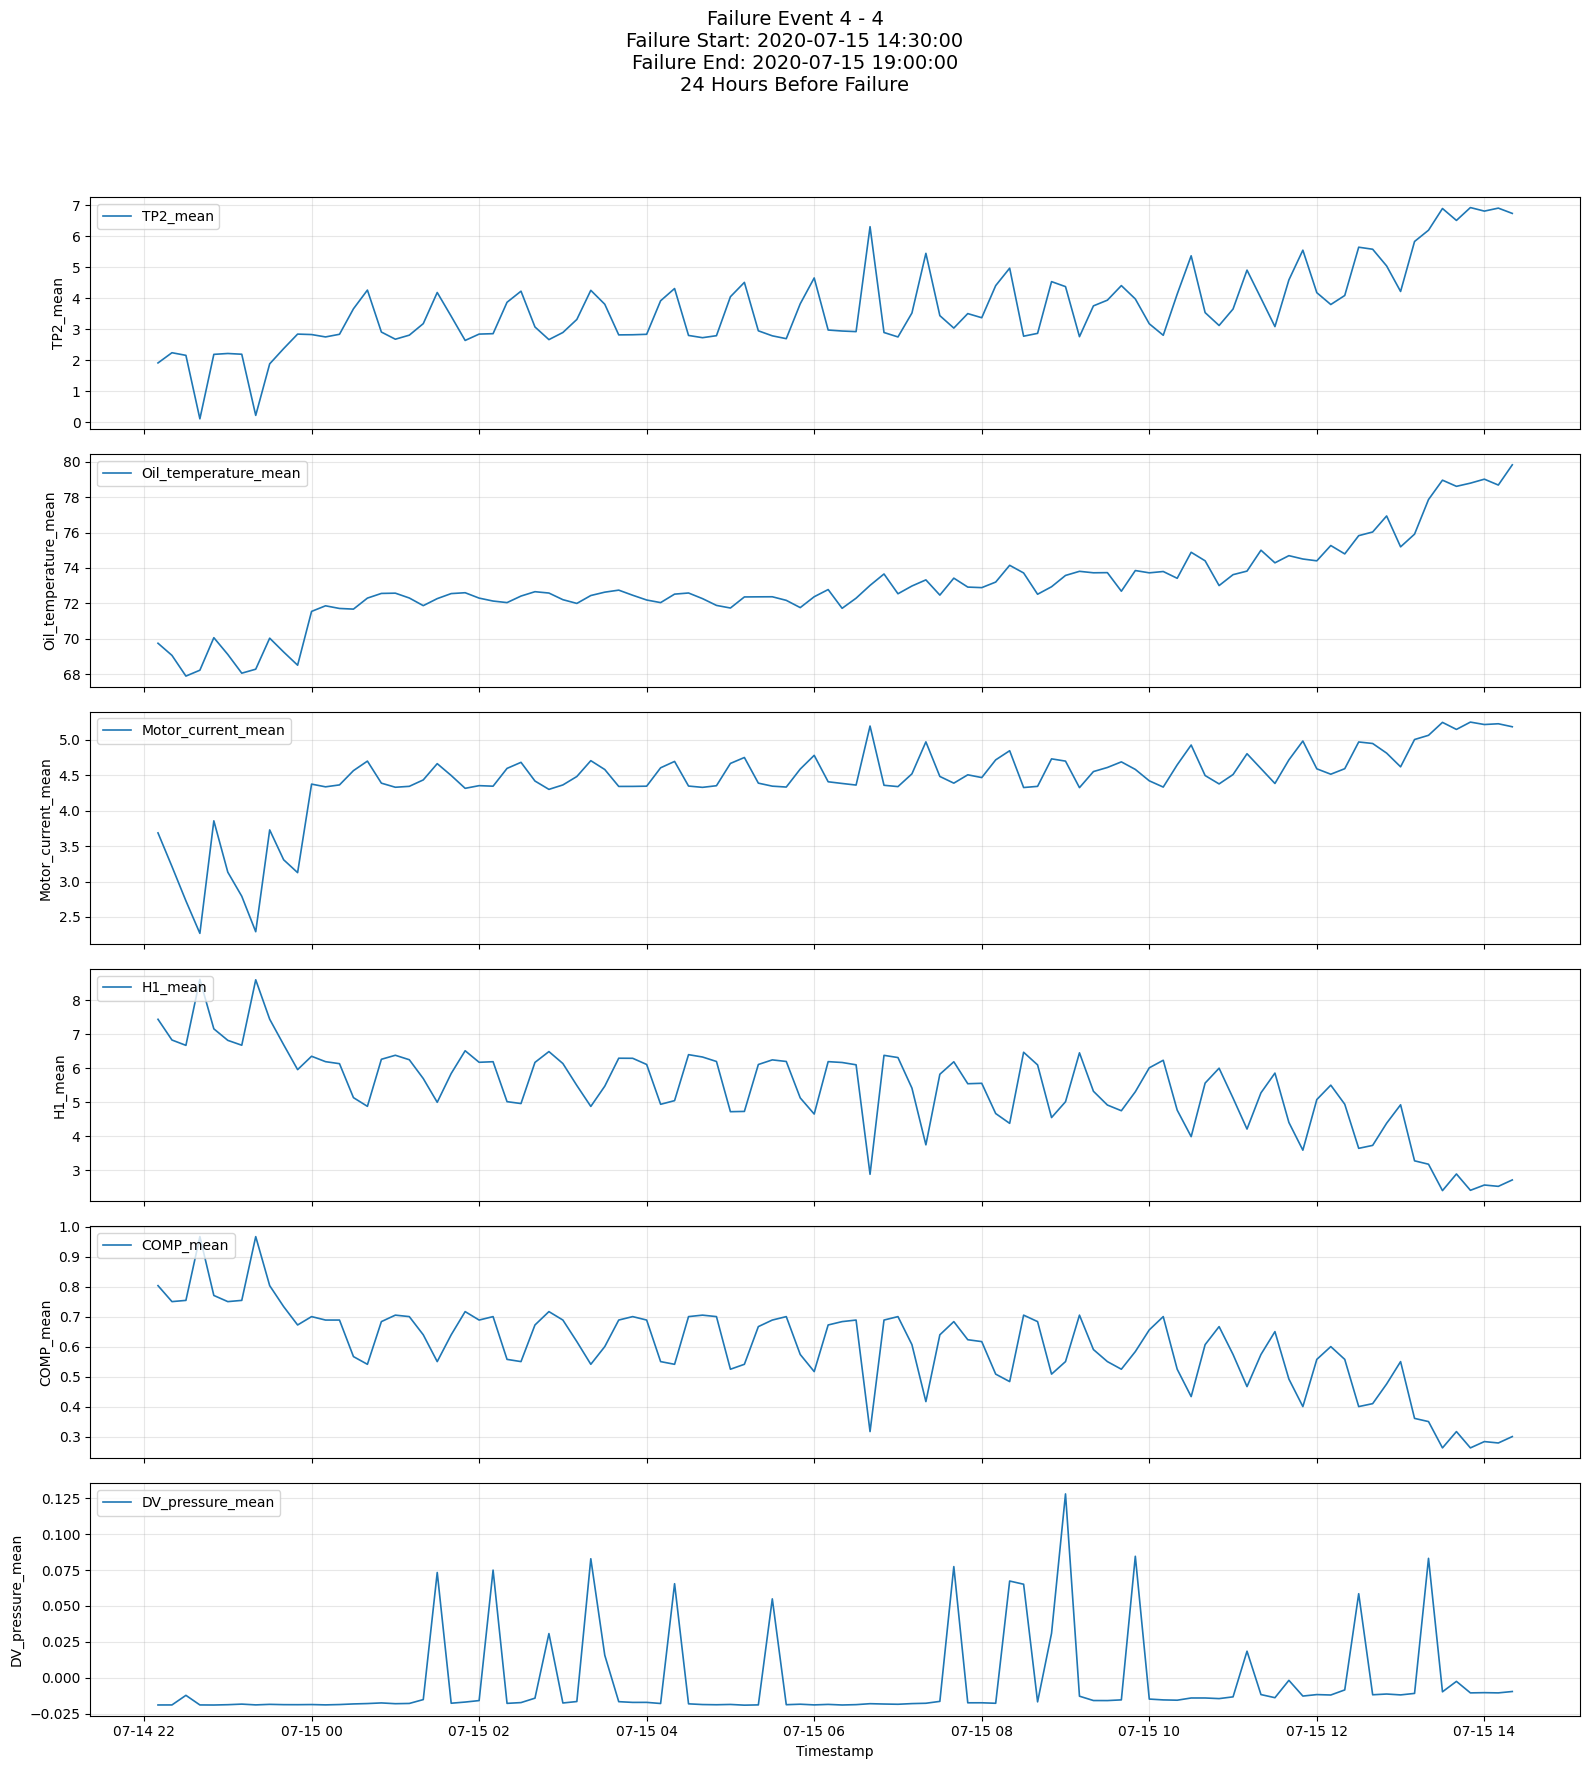

In [27]:
import matplotlib.pyplot as plt

cols = ["TP2_mean","Oil_temperature_mean","Motor_current_mean","H1_mean","COMP_mean","DV_pressure_mean"]

# Loop over failure events
for i, event in enumerate(failure_events, start=1):

    # Get failure start and end time
    failure_start = event["start"]
    failure_end = event["end"]

    # Define 24 hours before failure
    window_start = failure_start - pd.Timedelta(hours=24)

    # Select data from 24 hours before failure
    df_window = df_10min.loc[(df_10min.index >= window_start) & (df_10min.index < failure_start),cols]

    # Create subplots
    fig, axes = plt.subplots(nrows=len(cols),ncols=1,figsize=(16, 18),sharex=True)

    # Plot each feature
    for j, col in enumerate(cols):

        axes[j].plot(df_window.index,df_window[col],label=col,linewidth=1.2)

        axes[j].set_ylabel(col)
        axes[j].legend(loc="upper left")
        axes[j].grid(True, alpha=0.3)

    # Figure title
    fig.suptitle(
        f"Failure Event {i} - {event['failure_id']}\n"
        f"Failure Start: {failure_start}\n"
        f"Failure End: {failure_end}\n"
        f"24 Hours Before Failure",
        fontsize=14
    )

    plt.xlabel("Timestamp")
    plt.tight_layout(rect=[0, 0, 1, 0.94])

    plt.show()

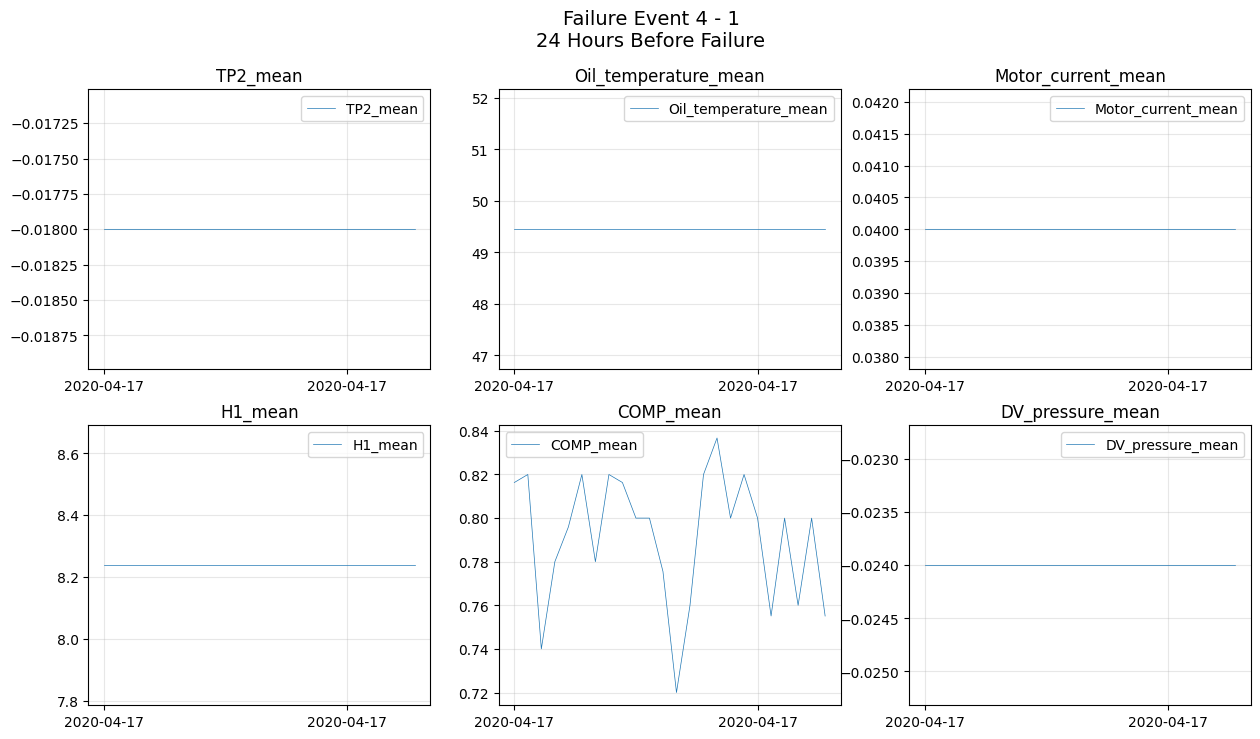

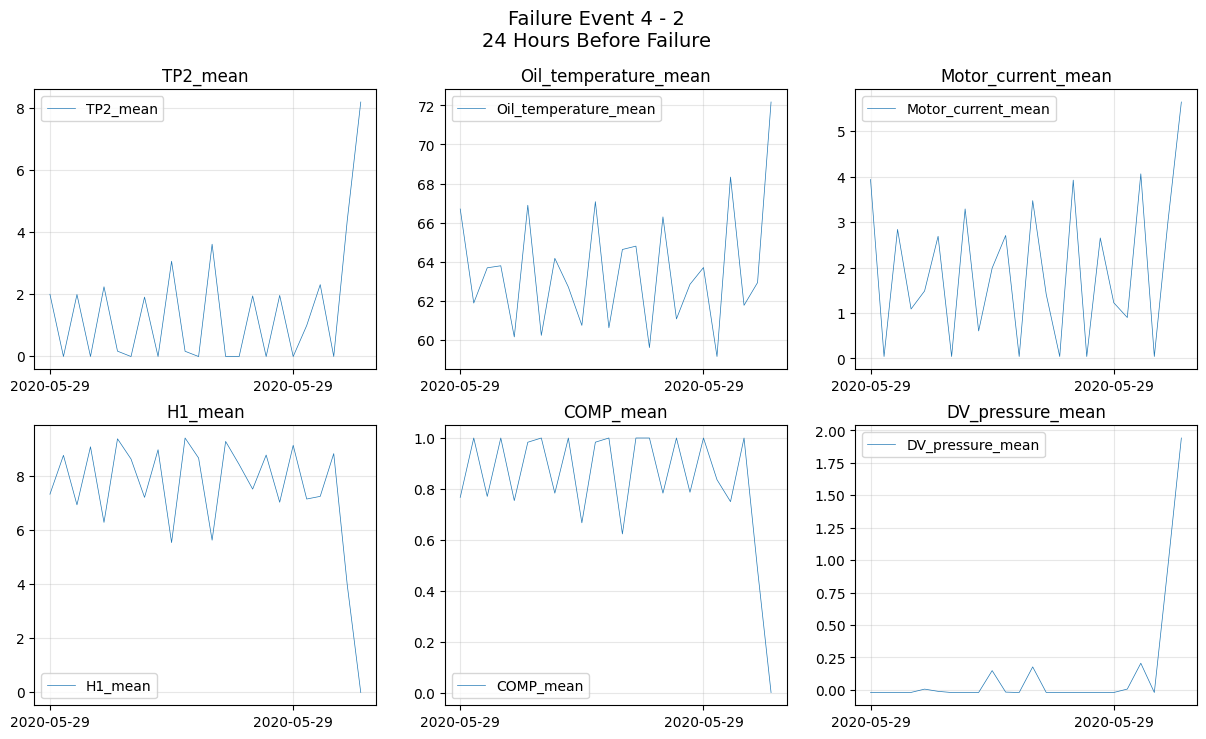

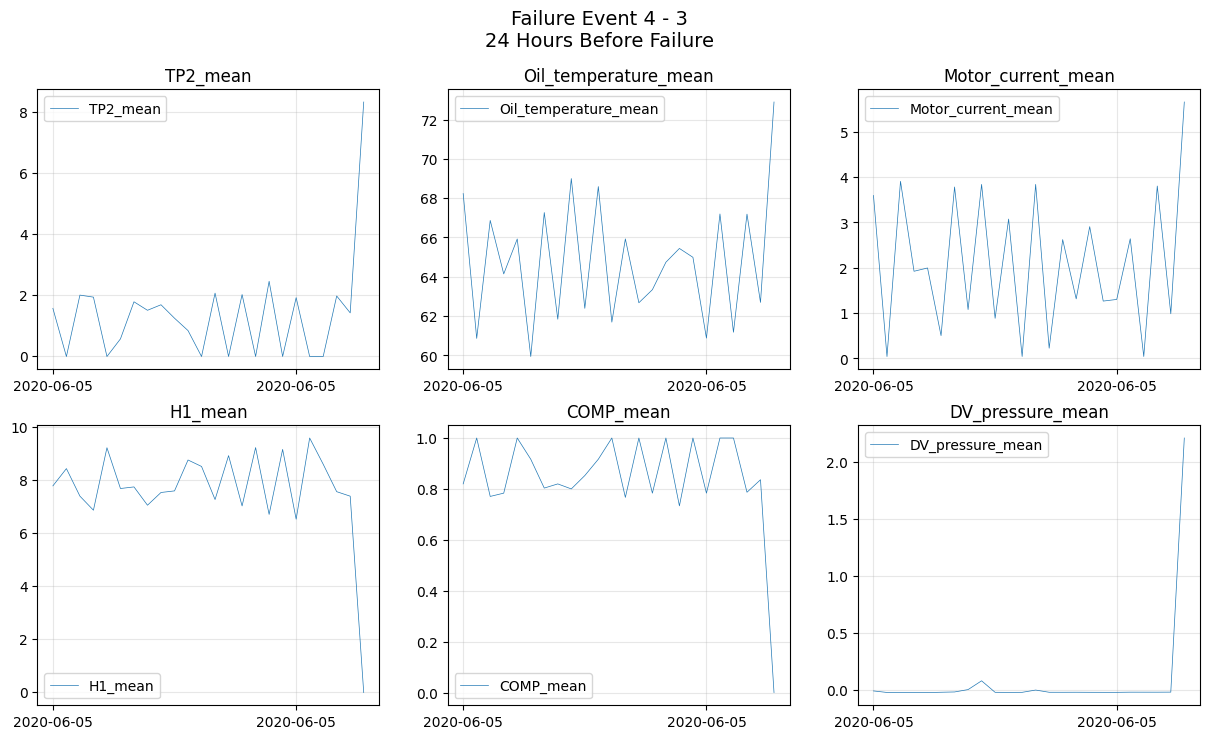

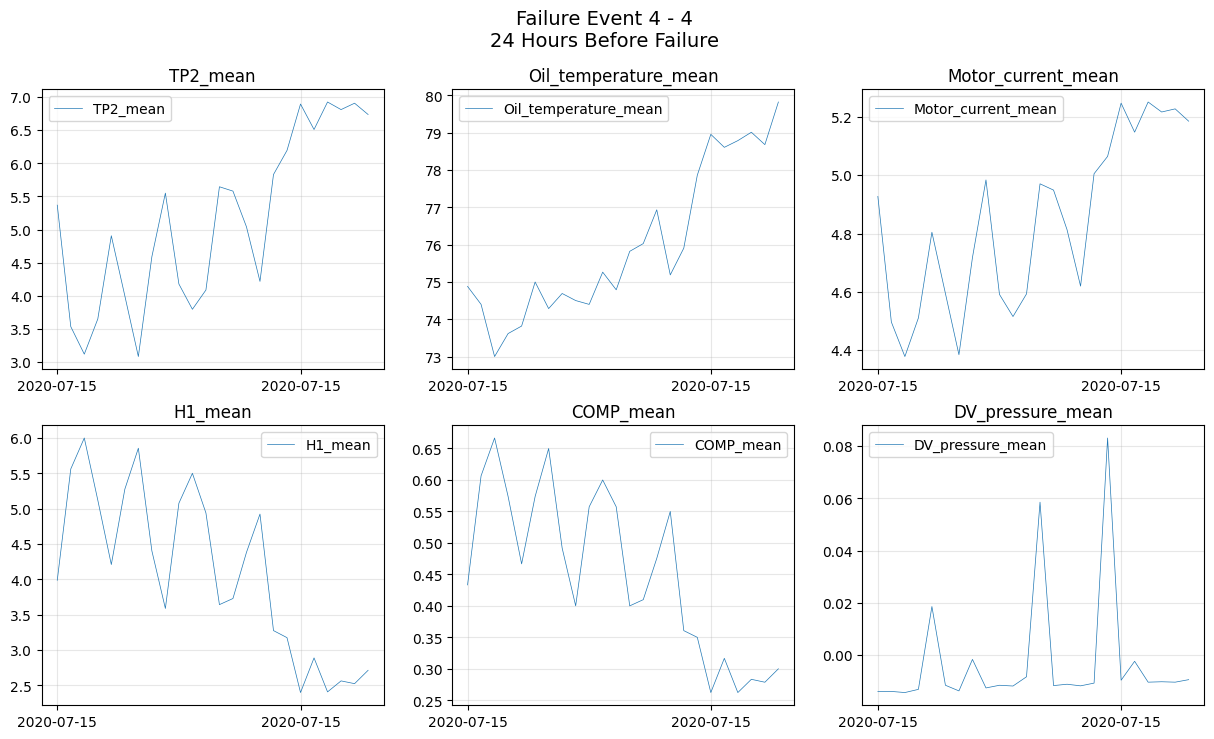

In [28]:
import matplotlib.pyplot as plt

cols = ["TP2_mean","Oil_temperature_mean","Motor_current_mean","H1_mean","COMP_mean","DV_pressure_mean"]

for event in failure_events[:]:
    start = event["start"] - pd.Timedelta(hours= 4)
    end = event["start"]
    window = df_10min.loc[(df_10min.index >= start) & (df_10min.index < end), cols]

    fig , axes = plt.subplots(nrows= 2, ncols= 3 , figsize = (15,8))
    ax = axes.flatten()
    for j, col in enumerate(cols):
        ax[j].plot(window.index, window[col], label = col, linewidth = 0.5)
        ax[j].set_xticks(window.index[::18])
      
        ax[j].set_title(col)
        ax[j].legend()
        ax[j].grid(True, alpha=0.3)
        fig.suptitle(f"Failure Event {i} - {event['failure_id']}\n"f"24 Hours Before Failure",fontsize=14)
    plt.show()


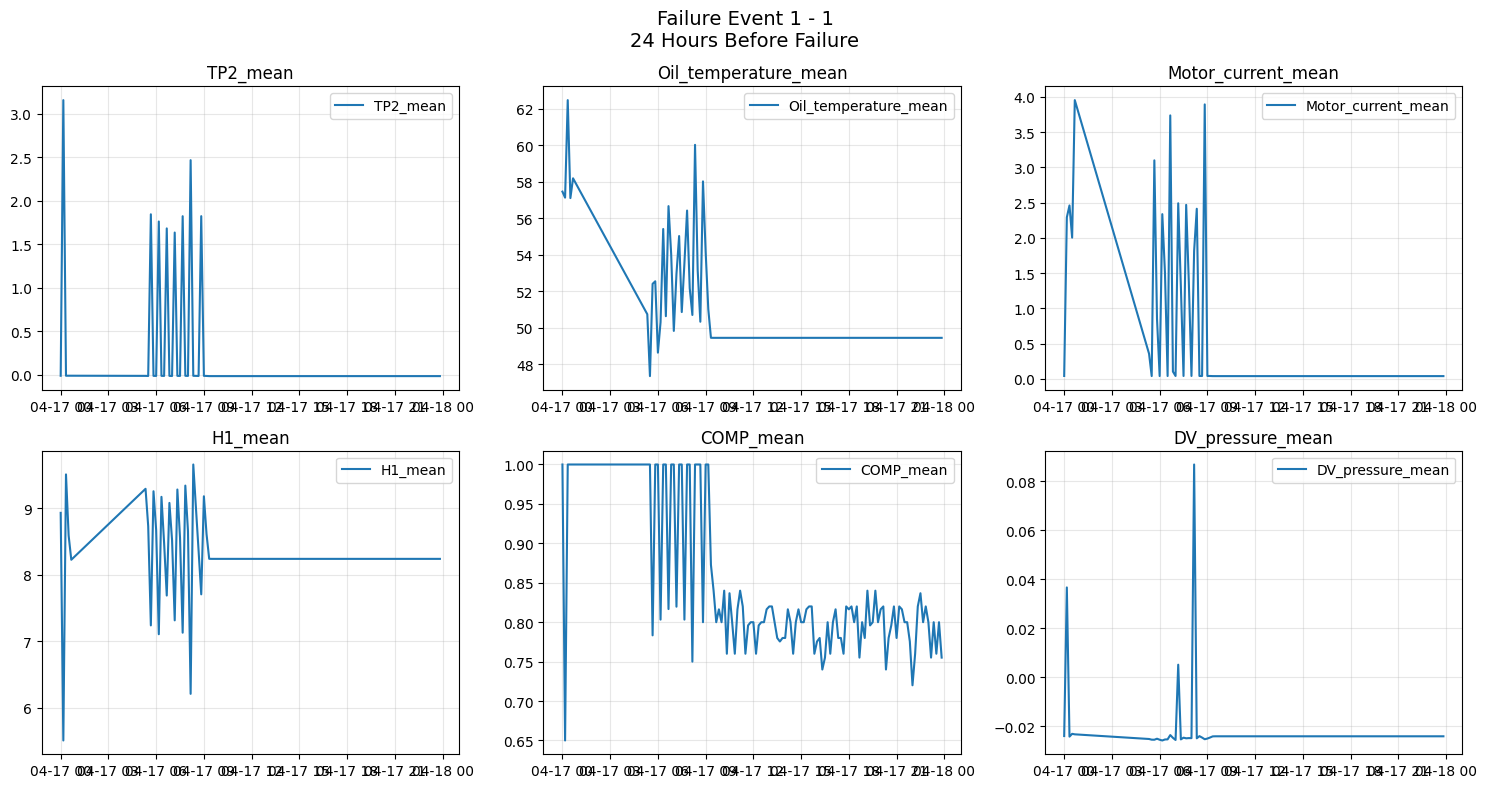

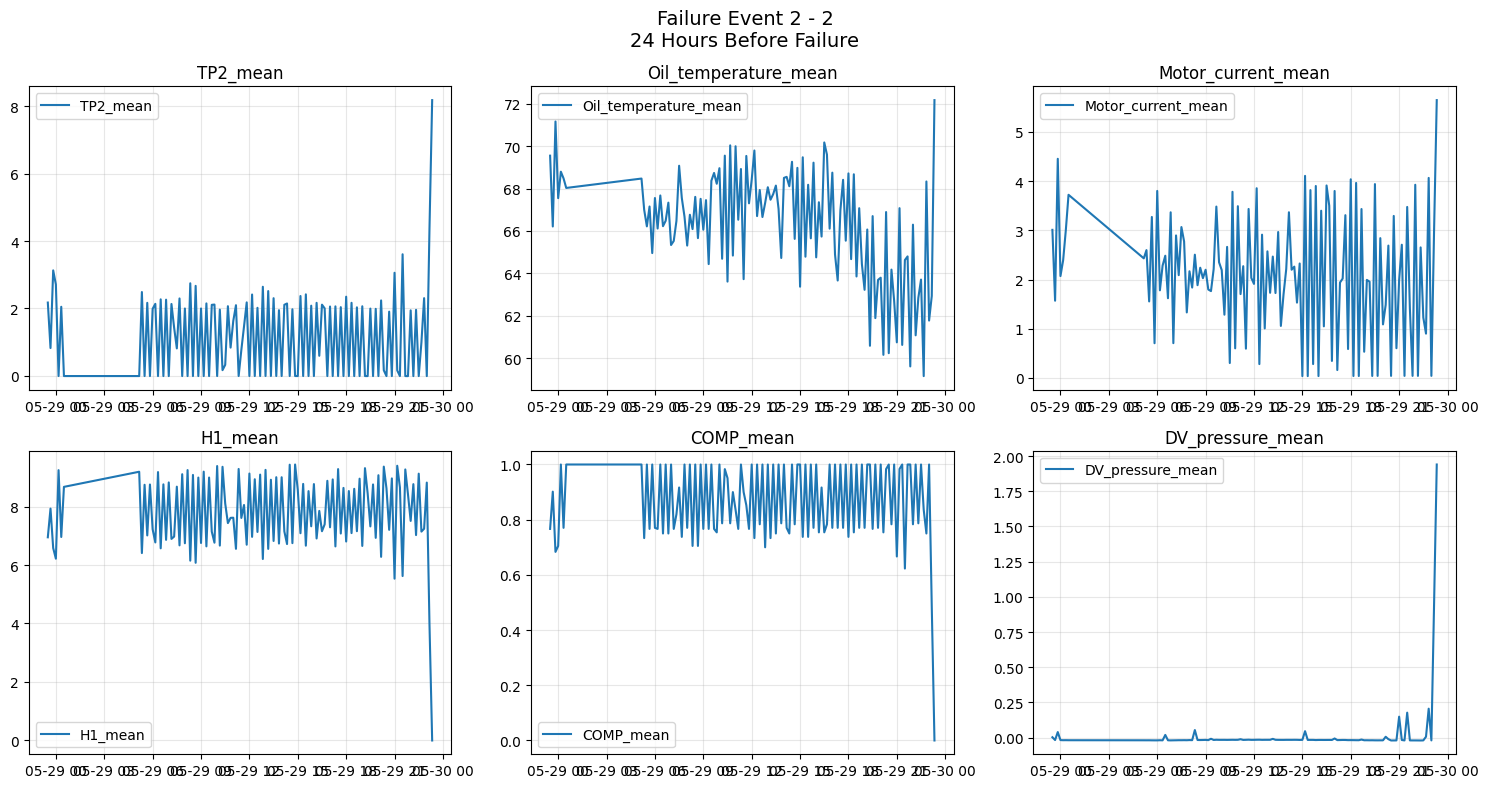

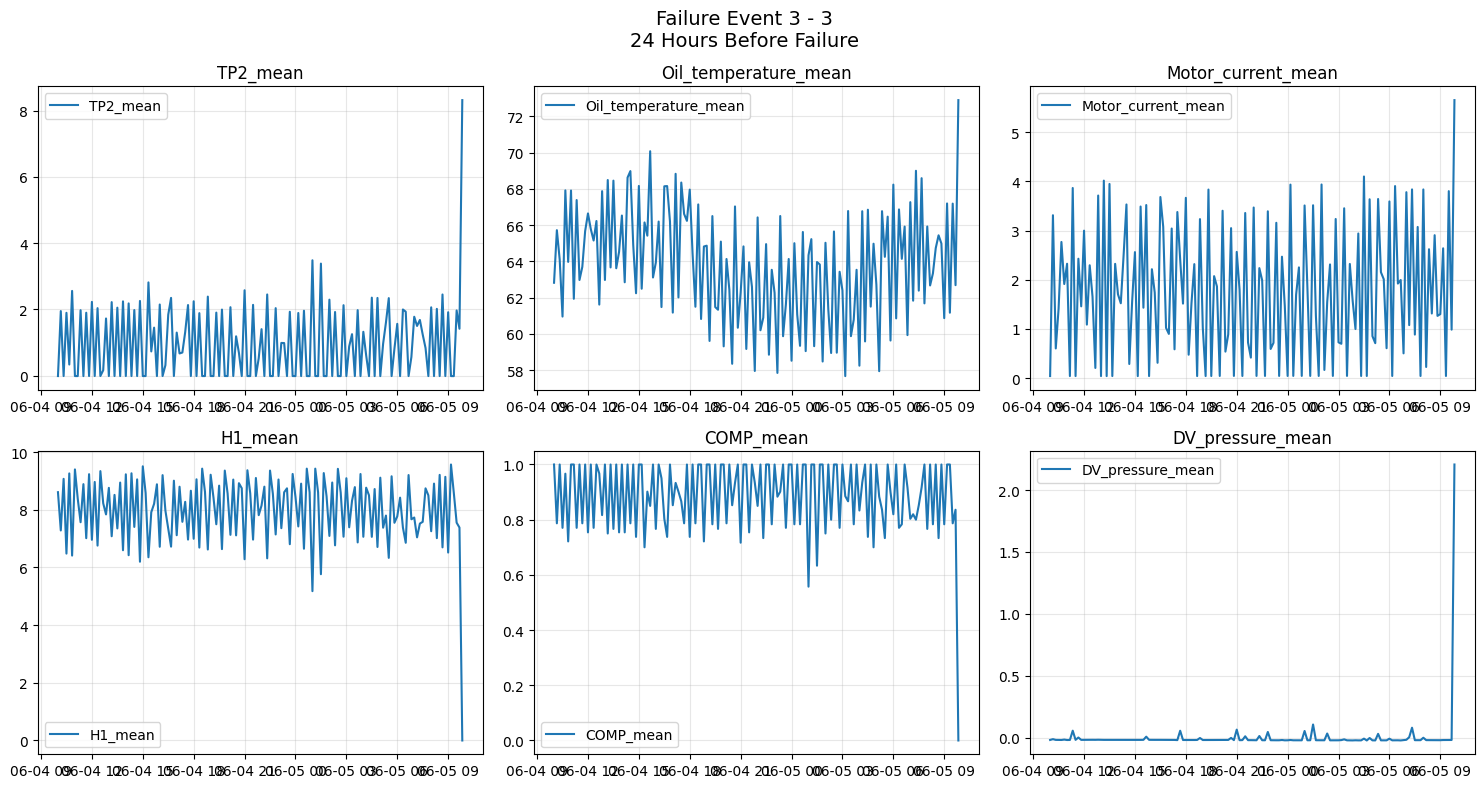

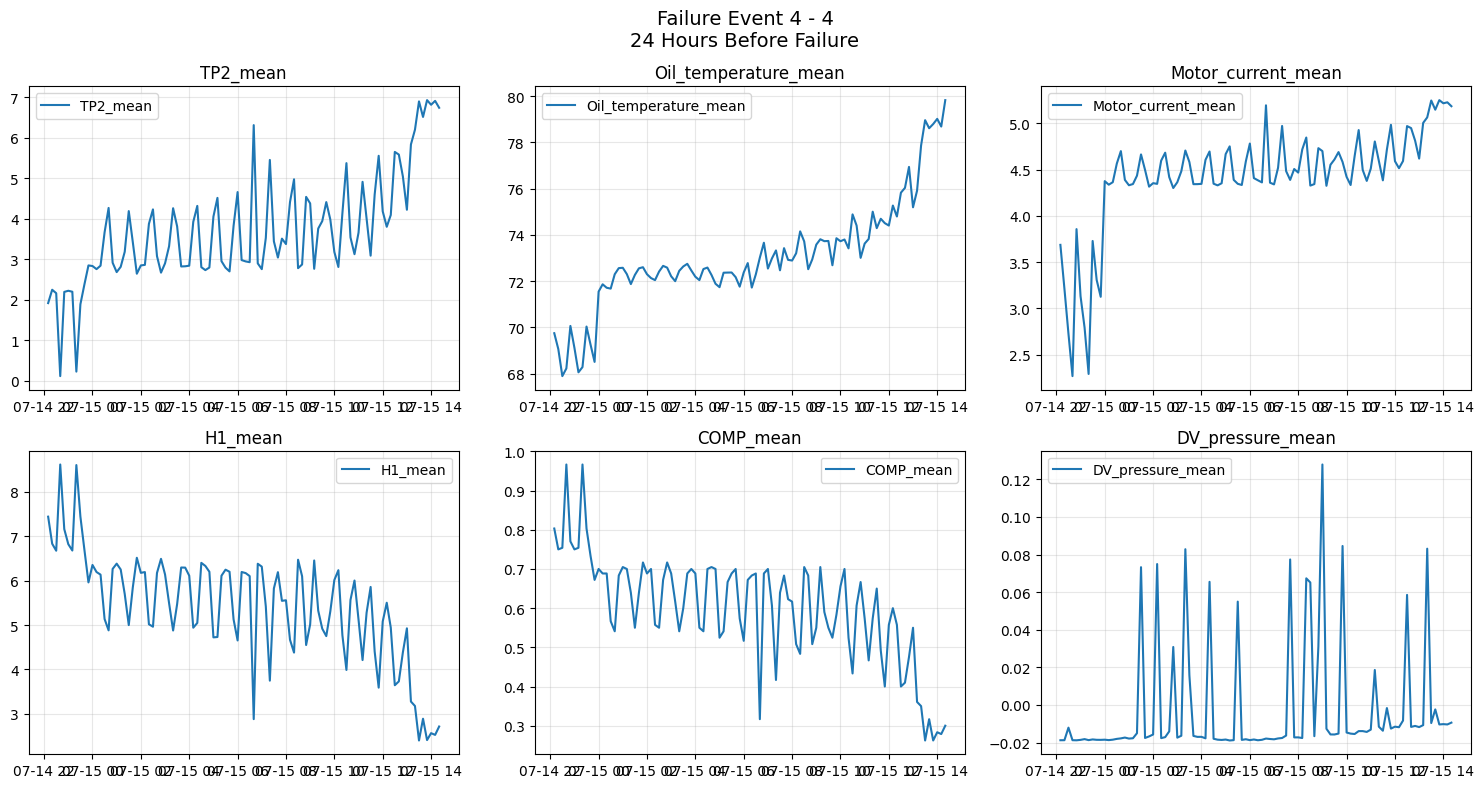

In [29]:
import matplotlib.pyplot as plt

cols = [
    "TP2_mean",
    "Oil_temperature_mean",
    "Motor_current_mean",
    "H1_mean",
    "COMP_mean",
    "DV_pressure_mean"
]

for i, event in enumerate(failure_events, start=1):

    start = event["start"] - pd.Timedelta(hours=24)
    end = event["start"]

    window = (df_10min.index >= start) & (df_10min.index < end)

    df_window = df_10min.loc[window, cols]

    fig, axes = plt.subplots(
        nrows=2,
        ncols=3,
        figsize=(15, 8)
    )

    ax = axes.flatten()

    for j, col in enumerate(cols):

        ax[j].plot(
            df_window.index,
            df_window[col],
            label=col,
            linewidth=1.5
        )

        ax[j].set_title(col)
        ax[j].legend()
        ax[j].grid(True, alpha=0.3)

    fig.suptitle(
        f"Failure Event {i} - {event['failure_id']}\n"
        f"24 Hours Before Failure",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()